In [ ]:
import hashlib
import json
import sys

import marimo as mo
import matplotlib.pyplot as plt

sys.path.insert(0, str(mo.notebook_dir()))
import dashboard_data

# Why did Medicare ACOs reset their benchmarks early? Results

This notebook reports the results of the pre-registered study
([OSF registration c53w9](https://osf.io/c53w9/), DOI 10.17605/OSF.IO/C53W9; plan and code at commit `a4064f5`).
It only reads the pipeline's results files in `analysis/mssp-benchmark-ratchet/results/` and recomputes nothing.
The blog post is the authoritative report; the verdicts below use the same wording as its dashboard.

Units: "pp" is percentage points. Benchmark components are in percentage points of the ACO's benchmark.
Intervals are 95% equal-tailed intervals; p-values are two-sided.

In [ ]:
results_dir = dashboard_data.DEFAULT_RESULTS
data = dashboard_data.build(results_dir)
raw = dashboard_data.load(results_dir)

In [ ]:
colors = {"ink": "#1f2933", "muted": "#5f6b7a", "grid": "#d9dee5", "mark": "#2b5c9e"}

def num(x, digits=1):
    if x is None:
        return ""
    text = f"{x:.{digits}f}"
    return text.lstrip("-") if float(text) == 0 else text.replace("-", "\u2212")

def pval(p):
    return "" if p is None else "< 0.001" if p < 0.001 else f"{p:.3f}"

def interval(r, digits=1):
    return "" if r.get("lo") is None else f"{num(r['lo'], digits)} to {num(r['hi'], digits)}"

def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return "\n".join(lines)

In [ ]:
def forest(ax, rows, xlabel, band=None):
    """One interval per row, top to bottom, with a zero line; band shades a prior's 95% range."""
    ys = list(range(len(rows)))[::-1]
    if band:
        ax.axvspan(-band, band, color=colors["grid"], alpha=0.5, lw=0)
    ax.axvline(0, color=colors["muted"], lw=1)
    for y, r in zip(ys, rows, strict=True):
        if r.get("lo") is not None:
            ax.plot([r["lo"], r["hi"]], [y, y], color=colors["mark"], lw=2, solid_capstyle="round")
        ax.plot(r["mean"], y, "o", color=colors["mark"], ms=6, mec="white", mew=1.5)
    ax.set_yticks(ys, [r["label"] for r in rows], color=colors["ink"])
    ax.set_xlabel(xlabel, color=colors["ink"])
    ax.tick_params(colors=colors["muted"], length=0)
    ax.grid(axis="x", color=colors["grid"], lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(colors["grid"])
    ax.set_ylim(-0.6, len(rows) - 0.4)

def figure(n_rows, height_per_row=0.45):
    fig, ax = plt.subplots(figsize=(7.5, 0.8 + height_per_row * n_rows), layout="constrained")
    return fig, ax

In [ ]:
_rows = []
for _stage in data["stages"]:
    _path = results_dir / f"{_stage['name']}.json"
    _rows.append([_stage["name"], f"`{raw[_stage['name']]['git_commit'][:7]}`", f"`{hashlib.sha256(_path.read_bytes()).hexdigest()[:16]}`"])
mo.md(
    "\n\n".join(
        [
            "## Provenance",
            f"Results are {'**synthetic**' if data['synthetic'] else 'from the real CMS data'}. Each stage records the commit it ran at; "
            "all of them contain the registered code unchanged (see `DEVIATIONS.md`).",
            table(["Stage", "Commit", "sha256 of results file (first 16)"], _rows),
        ]
    )
)

## Provenance

Results are from the real CMS data. Each stage records the commit it ran at; all of them contain the registered code unchanged (see `DEVIATIONS.md`).

| Stage | Commit | sha256 of results file (first 16) |
|---|---|---|
| validation | `fd1920f` | `046d82a1cc40548e` |
| power | `fd1920f` | `9d48835d8b87aac1` |
| confirm | `3e5cb9b` | `35bba7e38d3dd6e1` |
| robustness | `1debc2c` | `66f00ad1a01e2f1c` |
| did | `992d13f` | `8f3a6842df52d1eb` |
| conventional | `acc8b0e` | `3508370b700d1d00` |
| exploratory | `ff6e64b` | `280bbe10b738a284` |

In [ ]:
# The site's dashboard is built from the same function; confirm the committed copy matches these results.
_committed = json.loads((dashboard_data.DEFAULT_OUT).read_text())
_same = {k: v for k, v in _committed.items() if k != "built"} == {k: v for k, v in data.items() if k != "built"}
mo.md(f"The post's dashboard data (`data.json`) {'matches' if _same else '**does not match**'} these results.")

The post's dashboard data (`data.json`) matches these results.

In [ ]:
_v = data["validation"]
mo.md(
    f"""
    ## Validation of the benchmark approximation

    Passed: **{"yes" if _v["passed"] else "no"}**. Calibration applied: {"yes" if _v["calibrated"] else "no"}.
    Measurement-error SD used in the decision model (pp of benchmark): {num(_v["sigma_v_model"], 2)}.
    """
)

## Validation of the benchmark approximation

Passed: **yes**. Calibration applied: no.
Measurement-error SD used in the decision model (pp of benchmark): 4.38.

In [ ]:
_c = data["comparisons"]["rows"]
_rows = [[r["label"], r["role"], f"{r['n_early']} / {r['n_stayer']}", num(r["mean"]), interval(r), pval(r["p"]), num(r["mde"]), r["verdict"] or ""] for r in _c]
mo.md(
    "\n\n".join(
        [
            "## Who renewed early (H2b, H2a, H1)",
            "Early renewers minus stayers (Bayesian bootstrap; p-values from stratified permutation).",
            table(["Comparison", "Role", "n early / stayers", "Difference", "95% interval", "p", "MDE", "Verdict"], _rows),
        ]
    )
)

## Who renewed early (H2b, H2a, H1)

Early renewers minus stayers (Bayesian bootstrap; p-values from stratified permutation).

| Comparison | Role | n early / stayers | Difference | 95% interval | p | MDE | Verdict |
|---|---|---|---|---|---|---|---|
| H2b regional pull | primary | 26 / 241 | 3.4 | 1.7 to 5.4 | < 0.001 | 2.5 | supported |
| H2a own-spending component | secondary | 26 / 241 | −2.1 | −3.8 to −0.5 | 0.003 | 1.8 | contradicted |
| H1 savings rate, PY2020 | descriptive | 29 / 277 | 1.9 | 0.7 to 3.3 | 0.010 | 2.7 |  |
| H1 savings rate, PY2021 | descriptive | 29 / 277 | 1.6 | 0.2 to 3.1 | 0.033 | 2.7 |  |
| Total expected gain | descriptive | 26 / 241 | −0.5 | −2.0 to 0.8 | 0.325 |  |  |
| Regional component | descriptive | 26 / 241 | 1.6 | 0.9 to 2.2 | < 0.001 |  |  |

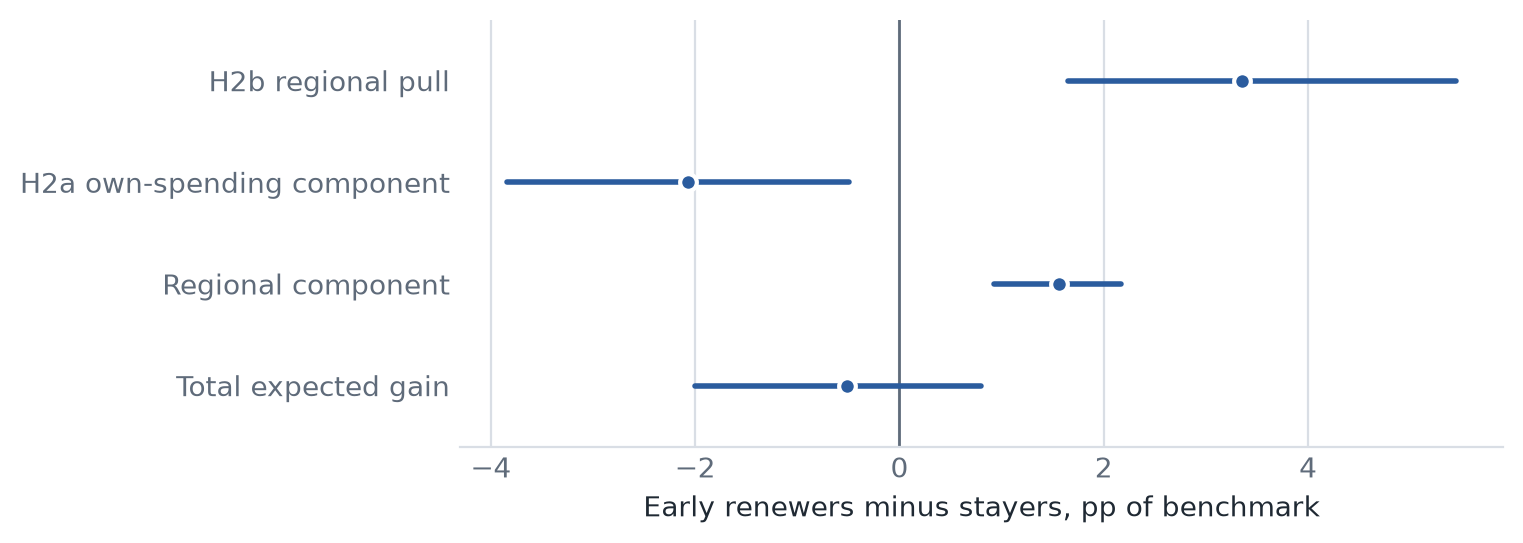

In [ ]:
_c = {r["key"]: r for r in data["comparisons"]["rows"]}
_fig, _ax = figure(4)
forest(_ax, [_c[k] for k in ("H2b_pull", "H2a_own", "regional_comp", "gain")], "Early renewers minus stayers, pp of benchmark")
_fig

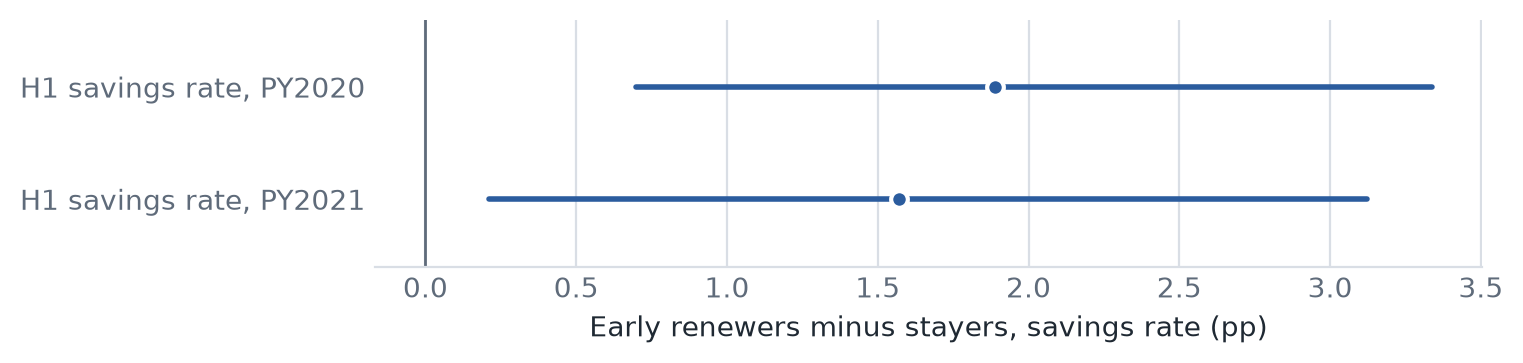

In [ ]:
_c = {r["key"]: r for r in data["comparisons"]["rows"]}
_fig, _ax = figure(2)
forest(_ax, [_c[k] for k in ("H1_sav_rate_2020", "H1_sav_rate_2021")], "Early renewers minus stayers, savings rate (pp)")
_fig

In [ ]:
_h3 = data["h3"]
_rows = [
    [
        r["label"],
        r["predicted"] or "",
        num(r["mean"], 2),
        f"{num(r['lo'], 2)} to {num(r['hi'], 2)}",
        num(r["p_positive"], 3),
        pval(r["test"]["p"]) if r["test"] else "",
        r["test"]["decision"] if r["test"] else "",
    ]
    for r in _h3["posterior"]["normal"]
]
_o = _h3["overall_test"]
_s = _h3["sample"]
mo.md(
    "\n\n".join(
        [
            "## H3: the decision model",
            "Bayesian logistic regression of early renewal, with measurement error on the own-spending component; "
            f"{_s['n']} ACOs, {_s['early']} early renewers ({_s['excluded']['early']} early renewers and {_s['excluded']['stayer']} stayers "
            f"excluded for a missing predictor). Converged: {'yes' if _h3['converged'] else 'no'}. Coefficients are log-odds per 2 SD of a "
            "continuous predictor; tests are by direct simulation under the reduced model.",
            table(["Coefficient", "Predicted", "Posterior mean", "95% interval", "P(> 0)", "p", "Decision"], _rows),
            f"Overall test ({_o['statistic']}): observed {num(_o['observed'], 2)}, p = {pval(_o['p_value'])} ({_o['n_shuffles']:,} shuffles). "
            f"Power to detect the planned effects: {_h3['power_note']}.",
        ]
    )
)

## H3: the decision model

Bayesian logistic regression of early renewal, with measurement error on the own-spending component; 206 ACOs, 24 early renewers (3 early renewers and 27 stayers excluded for a missing predictor). Converged: yes. Coefficients are log-odds per 2 SD of a continuous predictor; tests are by direct simulation under the reduced model.

| Coefficient | Predicted | Posterior mean | 95% interval | P(> 0) | p | Decision |
|---|---|---|---|---|---|---|
| Regional pull | + | 1.34 | 0.44 to 2.30 | 0.999 | 0.002 | supported |
| Own-spending component | + | −0.05 | −2.01 to 1.92 | 0.480 | 0.191 | undetermined |
| Higher BASIC level (C-E) | + | 1.34 | 0.38 to 2.31 | 0.998 | 0.003 | supported |
| 2020-01-01 cohort |  | 0.63 | −0.24 to 1.51 | 0.920 |  |  |
| Log assigned beneficiaries |  | 0.45 | −0.49 to 1.36 | 0.827 |  |  |
| High revenue |  | −0.53 | −1.69 to 0.59 | 0.182 |  |  |
| Prospective assignment |  | −0.77 | −1.79 to 0.19 | 0.058 |  |  |
| Later agreement |  | −0.67 | −1.62 to 0.31 | 0.089 |  |  |

Overall test (max |posterior mean| of core coefficients): observed 1.35, p = 0.004 (10,000 shuffles). Power to detect the planned effects: 17% (pull), 0% (own), 14% (BASIC level).

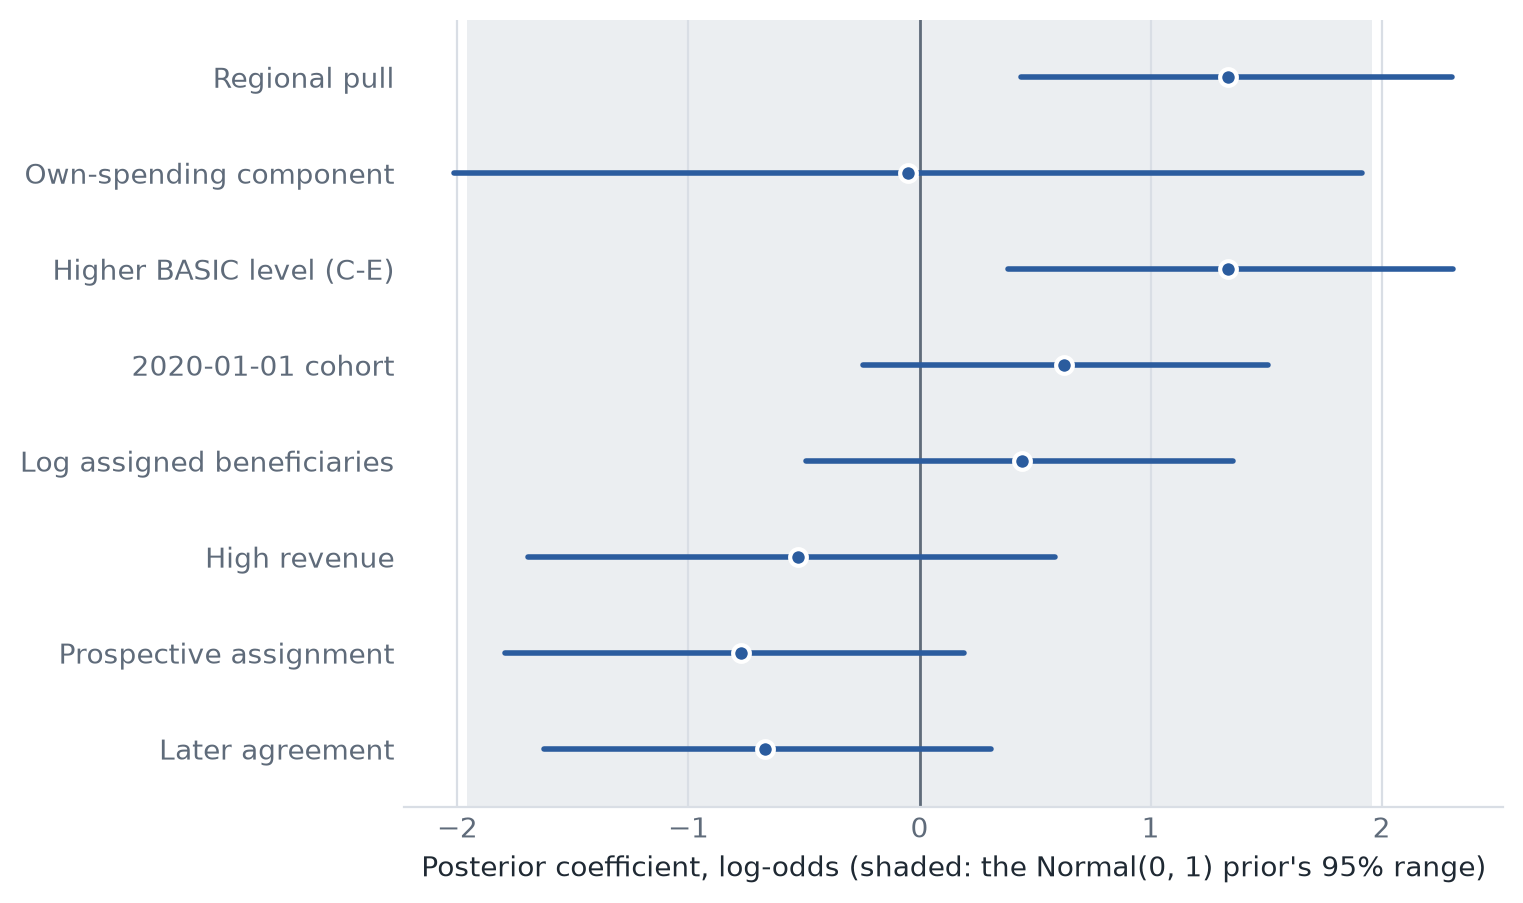

In [ ]:
_rows = data["h3"]["posterior"]["normal"]
_fig, _ax = figure(len(_rows))
forest(_ax, _rows, "Posterior coefficient, log-odds (shaded: the Normal(0, 1) prior's 95% range)", band=data["h3"]["prior_band"]["normal"])
_fig

In [ ]:
_h4 = data["h4"]
_rows = [[r["label"], r["role"], num(r["mean"]), interval(r), pval(r["p"])] for r in _h4["estimates"]]
_pre, _eq = _h4["pre_trend"], _h4["equivalence"]
mo.md(
    "\n\n".join(
        [
            "## H4: spending after renewal",
            f"Difference-in-differences in per-capita spending, in percent; {_h4['sample']['early']} early renewers and "
            f"{_h4['sample']['comparison']} comparison ACOs. Verdict: **{_h4['verdict']}** (MDE {num(_h4['mde_percent'])}%).",
            table(["Estimate", "Role", "Percent", "95% interval", "p"], _rows),
            f"Pre-trend slope difference: {num(_pre['mean'], 3)} ({num(_pre['lo'], 3)} to {num(_pre['hi'], 3)}), p = {pval(_pre['p'])}. "
            f"Equivalence condition: the pre-trend bound scaled to the post period is {num(_eq['scaled_bound'], 3)} against "
            f"|H4| = {num(_eq['abs_h4'], 3)}, so it {'holds' if _eq['holds'] else 'does not hold'}.",
        ]
    )
)

## H4: spending after renewal

Difference-in-differences in per-capita spending, in percent; 29 early renewers and 276 comparison ACOs. Verdict: **no detectable difference** (MDE 3.9%).

| Estimate | Role | Percent | 95% interval | p |
|---|---|---|---|---|
| H4 difference-in-differences | confirmatory | −0.4 | −4.0 to 2.5 | 0.778 |
| Trend-adjusted | robustness | −4.0 | −12.0 to 2.7 | 0.142 |
| Propensity-weighted | robustness | −0.5 |  | 0.668 |
| Risk-adjusted outcome | robustness | 0.3 | −2.0 to 2.5 | 0.849 |
| Balanced panel | robustness | −1.6 | −5.6 to 1.6 | 0.298 |
| 2020-01-01 cohort only | robustness | −2.9 | −8.3 to 1.3 | 0.130 |
| Two-way fixed effects | conventional | −1.5 | −5.4 to 2.4 | 0.438 |

Pre-trend slope difference: 0.007 (−0.023 to 0.048), p = 0.585. Equivalence condition: the pre-trend bound scaled to the post period is 0.115 against |H4| = 0.004, so it does not hold.

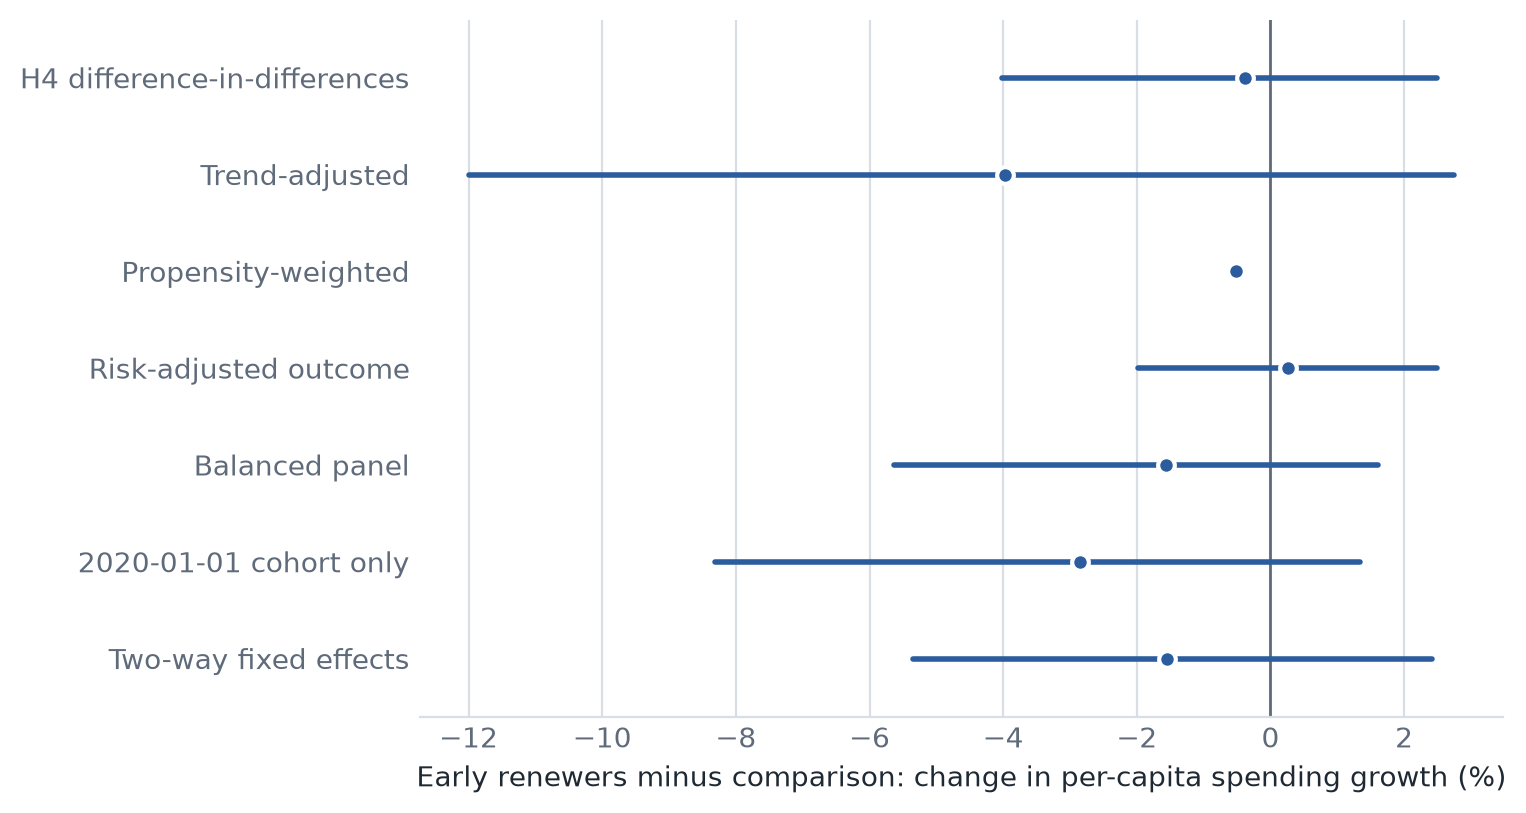

In [ ]:
_rows = data["h4"]["estimates"]
_fig, _ax = figure(len(_rows))
forest(_ax, _rows, "Early renewers minus comparison: change in per-capita spending growth (%)")
_fig

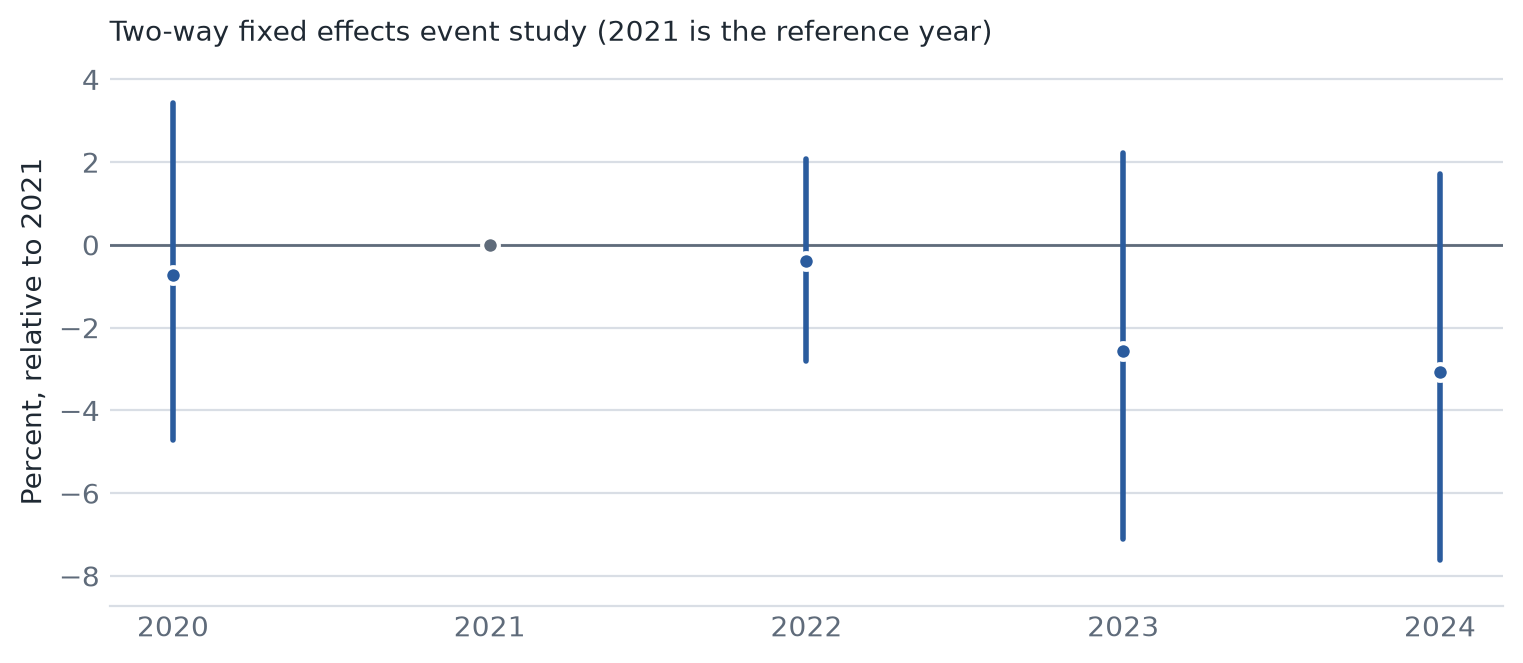

In [ ]:
_pts = data["h4"]["event_study"]
_fig, _ax = plt.subplots(figsize=(7.5, 3.2), layout="constrained")
_ax.axhline(0, color=colors["muted"], lw=1)
for _p in _pts:
    if not _p["reference"]:
        _ax.plot([_p["year"], _p["year"]], [_p["lo"], _p["hi"]], color=colors["mark"], lw=2, solid_capstyle="round")
    _ax.plot(_p["year"], _p["mean"], "o", color=colors["muted"] if _p["reference"] else colors["mark"], ms=6, mec="white", mew=1.5)
_ax.set_xticks([p["year"] for p in _pts])
_ax.margins(x=0.05, y=0.1)
_ax.set_ylabel("Percent, relative to 2021", color=colors["ink"])
_ax.set_title("Two-way fixed effects event study (2021 is the reference year)", color=colors["ink"], fontsize=10, loc="left")
_ax.tick_params(colors=colors["muted"], length=0)
_ax.grid(axis="y", color=colors["grid"], lw=0.8)
_ax.set_axisbelow(True)
for _side in ("top", "right", "left"):
    _ax.spines[_side].set_visible(False)
_ax.spines["bottom"].set_color(colors["grid"])
_fig

In [ ]:
_rows = [[r["claim"], r["confirmatory"], r["conventional"], "yes" if r["agree"] else "**no**"] for r in data["agreement"]]
mo.md(
    "## Registered and conventional methods\n\n"
    + table(["Claim", "Registered method", "Conventional method", "Agree"], _rows)
    + "\n\nThe plan's agreement table (section 5.7) calls H4 undetermined unless p < 0.05 in a direction; "
    'that is the same verdict as "no detectable difference" in the H4 section (section 7, rule 5).'
)

## Registered and conventional methods

| Claim | Registered method | Conventional method | Agree |
|---|---|---|---|
| H2b | supported | supported | yes |
| H2a | contradicted | contradicted | yes |
| H3 regional pull | supported | supported | yes |
| H3 own-spending component | undetermined | undetermined | yes |
| H3 higher BASIC level | supported | supported | yes |
| H4 | undetermined | undetermined | yes |

The plan's agreement table (section 5.7) calls H4 undetermined unless p < 0.05 in a direction; that is the same verdict as "no detectable difference" in the H4 section (section 7, rule 5).

In [ ]:
_rob = data["robustness"]
_parts = []
for _g in _rob["groups"] + _rob["h3"]:
    _digits = 2 if _g["unit"] == "log-odds" else 1
    _rows = [[r["label"], num(r["mean"], _digits), interval(r, _digits), pval(r["p"]), "" if r.get("converged", True) else "not converged"] for r in _g["rows"]]
    _parts.append(f"**{_g['label']}** ({_g['unit']})\n\n" + table(["Analysis", "Estimate", "95% interval", "p", ""], _rows))
mo.md(
    "## Robustness\n\nThe plan's section 5.5 items that rerun each confirmatory estimate. They do not change the "
    "decisions. H3 rows are the coefficient in each refit.\n\n" + "\n\n".join(_parts)
)

## Robustness

The plan's section 5.5 items that rerun each confirmatory estimate. They do not change the decisions. H3 rows are the coefficient in each refit.

**H2b regional pull** (pp of benchmark)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | 3.4 | 1.7 to 5.4 | < 0.001 |  |
| Regression, cohort only (5.3) | 2.1 | 0.5 to 3.8 |  |  |
| Regression + track, level and size (item 1) | 2.2 | 0.7 to 3.8 |  |  |
| Difference in medians (item 2) | 2.8 | 0.1 to 5.2 | < 0.001 |  |
| 2020-01-01 cohort only (item 3) | 3.7 | 1.8 to 5.5 | 0.001 |  |
| Unadjusted county spending (item 9) | 6.9 | 2.4 to 12.4 | 0.002 |  |

**H2a own-spending component** (pp of benchmark)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | −2.1 | −3.8 to −0.5 | 0.003 |  |
| Regression, cohort only (5.3) | −1.5 | −2.8 to −0.3 |  |  |
| Regression + track, level and size (item 1) | −1.3 | −2.6 to 0.0 |  |  |
| Difference in medians (item 2) | −1.4 | −3.2 to 0.0 | 0.085 |  |
| 2020-01-01 cohort only (item 3) | −1.8 | −4.2 to 0.5 | 0.043 |  |
| BY2-BY3 only in step 1 (item 6) | −1.9 | −3.7 to −0.2 | 0.012 |  |
| Complete cases (item 8) | −2.1 | −3.9 to −0.5 | 0.005 |  |

**H1 savings rate, PY2020** (pp)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | 1.9 | 0.7 to 3.3 | 0.010 |  |
| Regression, cohort only (5.3) | 1.5 | 0.2 to 2.9 |  |  |
| Regression + track, level and size (item 1) | 1.2 | −0.1 to 2.6 |  |  |
| Difference in medians (item 2) | 1.4 | −0.1 to 3.3 | 0.061 |  |
| 2020-01-01 cohort only (item 3) | 1.8 | 0.5 to 3.3 | 0.028 |  |

**Total expected gain** (pp of benchmark)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | −0.5 | −2.0 to 0.8 | 0.325 |  |
| Complete cases (item 8) | −0.5 | −2.0 to 0.8 | 0.333 |  |

**Regional component** (pp of benchmark)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | 1.6 | 0.9 to 2.2 | < 0.001 |  |
| Complete cases (item 8) | 1.6 | 0.9 to 2.2 | < 0.001 |  |

**Regional pull** (log-odds)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | 1.34 | 0.44 to 2.30 |  |  |
| Firth logistic regression (item 5) | 1.33 | 0.25 to 2.54 | 0.004 |  |
| 2020-01-01 cohort only (item 3) | 1.15 | −0.02 to 2.39 |  |  |
| BY2-BY3 only in step 1 (item 6) | 1.33 | 0.42 to 2.26 |  |  |
| No measurement-error model (item 7) | 1.22 | 0.34 to 2.20 |  |  |
| Complete cases (item 8) | 1.34 | 0.38 to 2.32 |  |  |
| Unadjusted county spending (item 9) | 0.75 | −0.02 to 1.56 |  |  |

**Own-spending component** (log-odds)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | −0.05 | −2.01 to 1.92 |  |  |
| Firth logistic regression (item 5) | −0.65 | −1.74 to 0.30 | 0.183 |  |
| 2020-01-01 cohort only (item 3) | −0.03 | −1.97 to 1.96 |  |  |
| BY2-BY3 only in step 1 (item 6) | −0.02 | −1.98 to 1.97 |  |  |
| No measurement-error model (item 7) | −0.64 | −1.51 to 0.23 |  |  |
| Complete cases (item 8) | −0.06 | −2.04 to 1.95 |  |  |
| Unadjusted county spending (item 9) | −0.04 | −1.99 to 1.93 |  |  |

**Higher BASIC level (C-E)** (log-odds)

| Analysis | Estimate | 95% interval | p |  |
|---|---|---|---|---|
| Confirmatory | 1.34 | 0.38 to 2.31 |  |  |
| Firth logistic regression (item 5) | 1.55 | 0.53 to 2.70 | 0.006 |  |
| 2020-01-01 cohort only (item 3) | 1.57 | 0.42 to 2.76 |  |  |
| BY2-BY3 only in step 1 (item 6) | 1.33 | 0.41 to 2.28 |  |  |
| No measurement-error model (item 7) | 1.26 | 0.33 to 2.23 |  |  |
| Complete cases (item 8) | 1.34 | 0.41 to 2.32 |  |  |
| Unadjusted county spending (item 9) | 1.52 | 0.61 to 2.47 |  |  |

In [ ]:
_exp = data["exploratory"]
_parts = []
for _g in _exp["alternative_exposures"]:
    _digits = 2 if _g["unit"] == "log-odds" else 1
    _rows = [[r["label"], num(r["mean"], _digits), interval(r, _digits), pval(r["p"])] for r in _g["rows"]]
    _parts.append(f"**{_g['label']}** ({_g['unit']})\n\n" + table(["Measure", "Estimate", "95% interval", "p"], _rows))
if _exp["region"]:
    _rows = [[r["label"], num(r["mean"], 2), interval(r, 2)] for r in _exp["region"]["rows"]]
    _parts.append("**Census region in the H3 model** (log-odds)\n\n" + table(["Region", "Posterior mean", "95% interval"], _rows))
_groups = _exp["groups"]
_rows = [[label] + [f"{num(_groups[g][v]['mean'])} (n = {_groups[g][v]['n']})" for g in _groups] for v, label in _exp["described"].items()]
_names = {"early": "Early renewers", "leaver": "Leavers", "stayer": "Stayers"}
_parts.append("**Means by group**\n\n" + table(["Variable"] + [_names.get(g, g) for g in _groups], _rows))
mo.md("## Exploratory\n\nLabeled exploratory in the plan (section 5.6): no verdicts.\n\n" + "\n\n".join(_parts))

## Exploratory

Labeled exploratory in the plan (section 5.6): no verdicts.

**H2b, early renewers minus stayers** (pp of benchmark)

| Measure | Estimate | 95% interval | p |
|---|---|---|---|
| Regional pull (confirmatory) | 3.4 | 1.7 to 5.4 | < 0.001 |
| Pull weighted by phase-in weight w | 1.6 | 0.7 to 2.6 | < 0.001 |
| Capped regional component | 1.6 | 0.9 to 2.2 | < 0.001 |

**H3 coefficient on the pull measure** (log-odds)

| Measure | Estimate | 95% interval | p |
|---|---|---|---|
| Regional pull (confirmatory) | 1.34 | 0.44 to 2.30 |  |
| Pull weighted by phase-in weight w | 1.20 | 0.40 to 2.04 |  |
| Capped regional component | 1.49 | 0.57 to 2.45 |  |
| Census region added | 1.43 | 0.46 to 2.41 |  |

**Census region in the H3 model** (log-odds)

| Region | Posterior mean | 95% interval |
|---|---|---|
| Midwest vs Northeast | 0.35 | −0.85 to 1.50 |
| South vs Northeast | −0.12 | −1.12 to 0.89 |
| West vs Northeast | 0.09 | −1.21 to 1.38 |

**Means by group**

| Variable | Early renewers | Leavers | Stayers |
|---|---|---|---|
| Savings rate, PY2020 (pp) | 6.4 (n = 29) | 2.7 (n = 28) | 4.6 (n = 277) |
| Regional pull (pp of benchmark) | 5.0 (n = 26) | 4.8 (n = 20) | 1.8 (n = 241) |
| Own-spending component (pp of benchmark) | −5.3 (n = 26) | −1.8 (n = 20) | −3.2 (n = 241) |
| Regional component (pp of benchmark) | 3.7 (n = 26) | 2.0 (n = 20) | 2.2 (n = 241) |